# Player Similarity Demo — Big Five (2015/16)

Compare eligible players across the Premier League, La Liga, Serie A, Ligue 1 and available Bundesliga matches. Players are compared within their playing role using a UMAP embedding and nearest-neighbor search.

**Coverage caveat:** The StatsBomb Open Data subset contains only 34 Bundesliga matches and 377 Ligue 1 matches for this season. These leagues therefore do not have equal coverage. UMAP distances are not similarity percentages or proof of player quality.

Run the cells in order. Change `search_name` to select a player and `comparison_rank` to compare against a neighbor.


In [85]:
import sys
print("Python:", sys.executable)

import pandas as pd
import matplotlib.pyplot as plt
import umap

print("All imports successful!")

Python: /Users/bilal/Desktop/football-player-similarity/.venv/bin/python
All imports successful!


In [86]:
from pathlib import Path
import importlib
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project root (works from project/ or project/notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Reload the module in case this notebook runs in an existing kernel
import src.similarity as similarity
importlib.reload(similarity)
from src.similarity import (
    build_role_matrices,
    build_umap_models,
    find_similar_players_umap,
)

LEAGUE_NAMES = {
    2: "Premier League",
    7: "Ligue 1",
    9: "Bundesliga",
    11: "La Liga",
    12: "Serie A",
}

# Fit one model per role, using players from all five leagues
matrices = build_role_matrices(
    data_path=ROOT / "data/processed/player_features_big5.parquet",
    config_path=ROOT / "config/role_feature_sets.json",
)
models = build_umap_models(matrices)

# The catalog uses a three-level index: competition, season, player
catalog = pd.concat([
    data["players"].assign(role=role)
    for role, data in matrices.items()
]).sort_values("player_name")
catalog["league"] = catalog.index.get_level_values(
    "competition_id"
).map(LEAGUE_NAMES)

print(f"Engine ready: {len(catalog)} eligible player profiles")
display(catalog.groupby("league").size().rename("eligible_players").to_frame())

Engine ready: 1373 eligible player profiles


,eligible_players
league,
Bundesliga,17
La Liga,344
Ligue 1,342
Premier League,327
Serie A,343


In [87]:
# Search for a player by name (case-insensitive)
search_name = "Messi"

matches = catalog[
    catalog["player_name"].str.contains(
        search_name, case=False, regex=False, na=False
    )
]

if len(matches) != 1:
    display(matches[["player_name", "league", "role", "minutes_played"]])
    raise ValueError(
        "Search must identify exactly one profile. "
        "Enter a more specific player name."
    )

# Every profile is identified by (competition_id, season_id, player_id)
player_key = tuple(int(v) for v in matches.index[0])
competition_id, season_id, player_id = player_key
role = matches.iloc[0]["role"]
name_a = matches.iloc[0]["player_name"]
label_a = f"{name_a} ({LEAGUE_NAMES[competition_id]})"

results = find_similar_players_umap(
    player_id=player_id,
    competition_id=competition_id,
    season_id=season_id,
    matrices=matrices,
    models=models,
    top_k=10,
)
results["league"] = results["competition_id"].map(LEAGUE_NAMES)

print(f"Selected player: {label_a}")
print(f"Role: {role} | Season: 2015/16")
print("UMAP distances are not similarity percentages.")
display(
    results[
        ["player_name", "league", "minutes_played", "distance"]
    ].round(3)
)

Selected player: Lionel Andrés Messi Cuccittini (La Liga)
Role: wide_player | Season: 2015/16
UMAP distances are not similarity percentages.


,player_name,league,minutes_played,distance
0,Alexis Alejandro Sánchez Sánchez,Premier League,2518.367,0.207
1,Neymar da Silva Santos Junior,La Liga,3138.650,0.238
2,Lorenzo Insigne,Serie A,2634.783,0.298
3,Philippe Coutinho Correia,Premier League,2104.800,0.315
4,Ángel Fabián Di María Hernández,Ligue 1,2079.517,0.362
5,Rachid Ghezzal,Ligue 1,1669.500,0.405
6,Dries Mertens,Serie A,1192.050,0.563
7,Christian Dannemann Eriksen,Premier League,3043.200,0.651
8,Sérgio Paulo Barbosa Valente,La Liga,1135.400,0.695
9,Manuel Agudo Durán,La Liga,2555.717,0.701


Player statistics: Lionel Andrés Messi Cuccittini (La Liga)


,Statistic,Value
0,passes_attempted_per90,61.77
1,pass_completion_rate,0.80
2,progressive_passes_per90,8.59
3,key_passes_per90,2.37
4,crosses_per90,1.15
5,through_balls_per90,3.43
6,carries_per90,66.80
7,average_carry_length,6.50
8,progressive_carries_per90,7.02
9,dribbles_attempted_per90,7.73


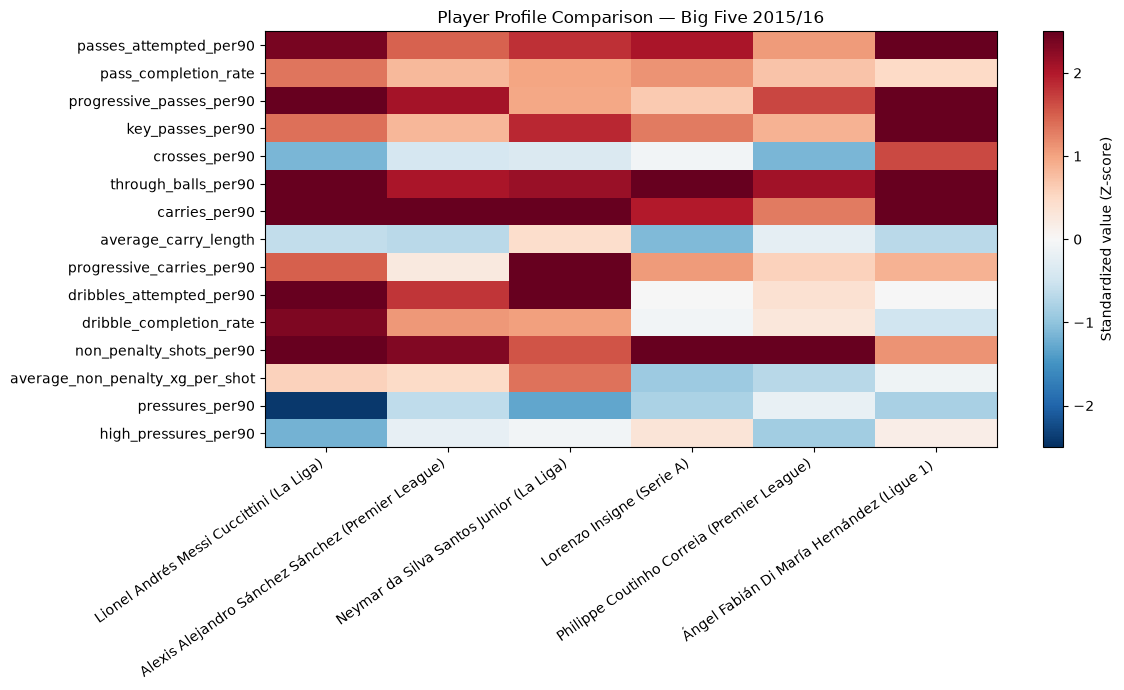

In [88]:
data = matrices[role]
X = data["X"]  # MultiIndex: competition_id, season_id, player_id

# Recover the selected player's original (unscaled) role features
original_values = data["scaler"].inverse_transform(
    X.loc[[player_key]]
)[0]
stats = pd.DataFrame({
    "Statistic": X.columns,
    "Value": original_values,
})
print(f"Player statistics: {label_a}")
display(stats.round(2))

# Compare the selected player and the top five UMAP neighbors
neighbor_keys = [
    tuple(int(row[col]) for col in [
        "competition_id", "season_id", "player_id"
    ])
    for _, row in results.head(5).iterrows()
]
heatmap_keys = [player_key] + neighbor_keys

heatmap = X.loc[heatmap_keys].T.copy()
heatmap.columns = [
    f"{data['players'].loc[key, 'player_name']} "
    f"({LEAGUE_NAMES[key[0]]})"
    for key in heatmap_keys
]

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(
    heatmap,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-2.5,
    vmax=2.5,
)
ax.set_xticks(range(len(heatmap.columns)))
ax.set_xticklabels(heatmap.columns, rotation=35, ha="right")
ax.set_yticks(range(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)
ax.set_title("Player Profile Comparison — Big Five 2015/16")
fig.colorbar(im, ax=ax, label="Standardized value (Z-score)")
plt.tight_layout()
plt.show()

## Player vs Player Comparison

Choose one of the 10 nearest neighbors with `comparison_rank` (1 to 10).

This comparison shows the 5 closest and 5 most different **original role features**, measured in standardized Z-score gaps. These are **not** an explanation of the nonlinear UMAP distance.


Lionel Andrés Messi Cuccittini (La Liga) vs Alexis Alejandro Sánchez Sánchez (Premier League)

5 most similar statistical features


,Lionel Andrés Messi Cuccittini (La Liga),Alexis Alejandro Sánchez Sánchez (Premier League),Z-score gap
average_carry_length,6.50,6.41,0.07
average_non_penalty_xg_per_shot,0.10,0.10,0.10
pass_completion_rate,0.80,0.77,0.52
key_passes_per90,2.37,2.04,0.54
crosses_per90,1.15,1.97,0.72



5 most different statistical features


,Lionel Andrés Messi Cuccittini (La Liga),Alexis Alejandro Sánchez Sánchez (Premier League),Z-score gap
through_balls_per90,3.43,0.96,7.73
pressures_per90,6.13,14.29,1.78
dribbles_attempted_per90,7.73,5.90,1.34
dribble_completion_rate,0.74,0.62,1.25
progressive_carries_per90,7.02,4.68,1.25


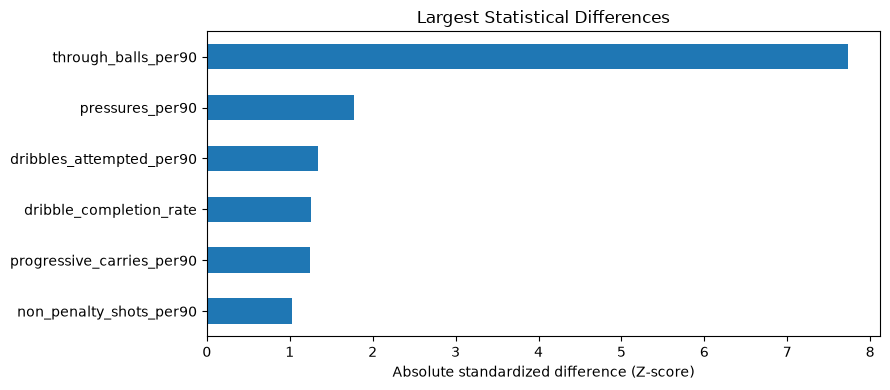

In [89]:
# Select one of the UMAP Top 10 neighbors
comparison_rank = 1
if not 1 <= comparison_rank <= len(results):
    raise ValueError(f"comparison_rank must be between 1 and {len(results)}")

neighbor = results.iloc[comparison_rank - 1]
comparison_key = tuple(int(neighbor[col]) for col in [
    "competition_id", "season_id", "player_id"
])
name_b = data["players"].loc[comparison_key, "player_name"]
label_b = f"{name_b} ({LEAGUE_NAMES[comparison_key[0]]})"

# Compare standardized vectors in the original feature space
a = X.loc[player_key]
b = X.loc[comparison_key]
original = pd.DataFrame(
    data["scaler"].inverse_transform(X.loc[[player_key, comparison_key]]),
    index=pd.MultiIndex.from_tuples(
        [player_key, comparison_key], names=X.index.names
    ),
    columns=X.columns,
)

comparison = pd.DataFrame({
    label_a: original.loc[player_key],
    label_b: original.loc[comparison_key],
    "Z-score gap": (a - b).abs(),
}).sort_values("Z-score gap")

print(f"{label_a} vs {label_b}")
print("\n5 most similar statistical features")
display(comparison.head(5).round(2))
print("\n5 most different statistical features")
display(comparison.tail(5).sort_values("Z-score gap", ascending=False).round(2))

largest_gaps = comparison.nlargest(6, "Z-score gap")
fig, ax = plt.subplots(figsize=(9, 4))
largest_gaps["Z-score gap"].sort_values().plot.barh(ax=ax)
ax.set_title("Largest Statistical Differences")
ax.set_xlabel("Absolute standardized difference (Z-score)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [90]:
# Verify the event data required by the pitch visualizations
from mplsoccer import Pitch
import numpy as np

EVENTS_DIR = ROOT / "data/processed/events"
PLAYER_MATCH_PATH = ROOT / "data/processed/player_match_big5.parquet"

print("Events directory exists:", EVENTS_DIR.is_dir())
print("Processed event files:", len(list(EVENTS_DIR.glob("events_*.parquet"))))
print("Player-match table exists:", PLAYER_MATCH_PATH.is_file())

Events directory exists: True
Processed event files: 1551
Player-match table exists: True


In [91]:
import numpy as np
import pandas as pd
from mplsoccer import Pitch

# Use the match catalog to restrict each player to their own league/season.
# This prevents events from a different competition from being mixed in.
player_matches = pd.read_parquet(
    PLAYER_MATCH_PATH,
    columns=["match_id", "competition_id", "season_id", "player_id"],
)

selected_keys = [player_key, comparison_key]
selected_labels = [label_a, label_b]

# Map each match to the selected player profiles appearing in it
profiles_by_match = {}
for key in selected_keys:
    competition, season, pid = key
    relevant = player_matches[
        (player_matches["competition_id"] == competition)
        & (player_matches["season_id"] == season)
        & (player_matches["player_id"] == pid)
    ]
    if relevant.empty:
        raise ValueError(f"No player-match rows found for {key}")

    for mid in relevant["match_id"].astype(int):
        profiles_by_match.setdefault(mid, []).append(key)

# Read only the event files for those matches, not all 1,551 files
columns = [
    "player_id", "location", "is_pass", "pass_completed",
    "pass_end_location", "is_shot", "shot_statsbomb_xg", "is_goal",
]
parts = []
for match_id, keys_in_match in sorted(profiles_by_match.items()):
    file_path = EVENTS_DIR / f"events_{match_id}.parquet"
    if not file_path.exists():
        raise FileNotFoundError(f"Missing event file: {file_path}")

    events_in_match = pd.read_parquet(file_path, columns=columns)
    ids_in_match = [key[2] for key in keys_in_match]
    selected = events_in_match.loc[
        events_in_match["player_id"].isin(ids_in_match)
        & (
            events_in_match["is_pass"].fillna(False)
            | events_in_match["is_shot"].fillna(False)
        )
    ].copy()

    if not selected.empty:
        selected["competition_id"] = keys_in_match[0][0]
        selected["season_id"] = keys_in_match[0][1]
        parts.append(selected)

if not parts:
    raise ValueError("No pass or shot events found for these profiles.")

player_events = pd.concat(parts, ignore_index=True)

def profile_events(key):
    """Return only the events for one league-season-player profile."""
    competition, season, pid = key
    return player_events.loc[
        (player_events["competition_id"] == competition)
        & (player_events["season_id"] == season)
        & (player_events["player_id"] == pid)
    ].copy()


def extract_xy(series):
    """Convert StatsBomb [x, y] coordinates into numeric columns."""
    coords = [
        (float(v[0]), float(v[1]))
        if isinstance(v, (list, tuple, np.ndarray)) and len(v) >= 2
        else (np.nan, np.nan)
        for v in series
    ]
    return pd.DataFrame(coords, index=series.index, columns=["x", "y"])

print(f"Loaded {len(player_events)} pass/shot events from "
      f"{len(profiles_by_match)} relevant matches.")

Loaded 3683 pass/shot events from 63 relevant matches.


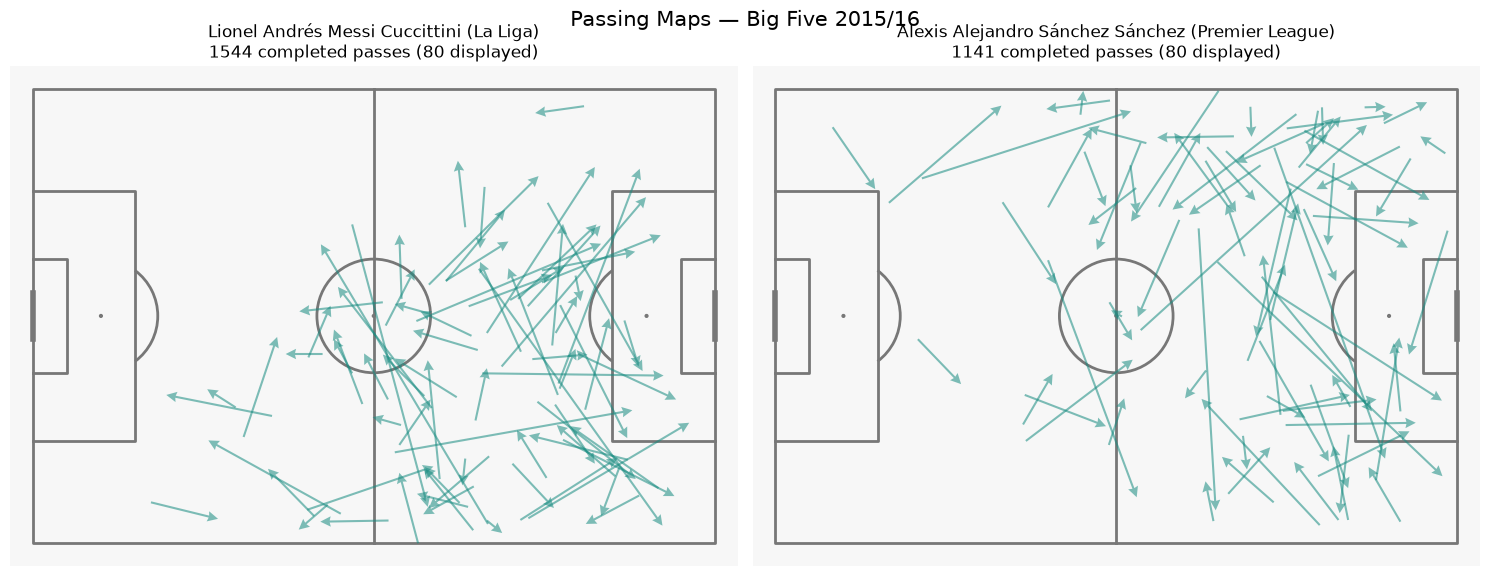

In [92]:
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#f7f7f7",
    line_color="#777777",
)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, key, name in zip(axes, selected_keys, selected_labels):
    events = profile_events(key)
    passes = events.loc[
        events["is_pass"].fillna(False)
        & events["pass_completed"].fillna(False)
    ].copy()

    start = extract_xy(passes["location"])
    end = extract_xy(passes["pass_end_location"])
    passes[["x", "y"]] = start
    passes[["end_x", "end_y"]] = end.to_numpy()
    passes = passes.dropna(subset=["x", "y", "end_x", "end_y"])

    # Reproducible sample to avoid overcrowding the pitch
    sample = passes.sample(n=min(80, len(passes)), random_state=42)
    pitch.draw(ax=ax)

    if not sample.empty:
        pitch.arrows(
            sample["x"], sample["y"],
            sample["end_x"], sample["end_y"],
            ax=ax, color="#168B80", alpha=0.55,
            width=1.5, headwidth=5,
        )

    ax.set_title(
        f"{name}\n{len(passes)} completed passes "
        f"({len(sample)} displayed)"
    )

fig.suptitle("Passing Maps — Big Five 2015/16", fontsize=15)
plt.tight_layout()
plt.show()

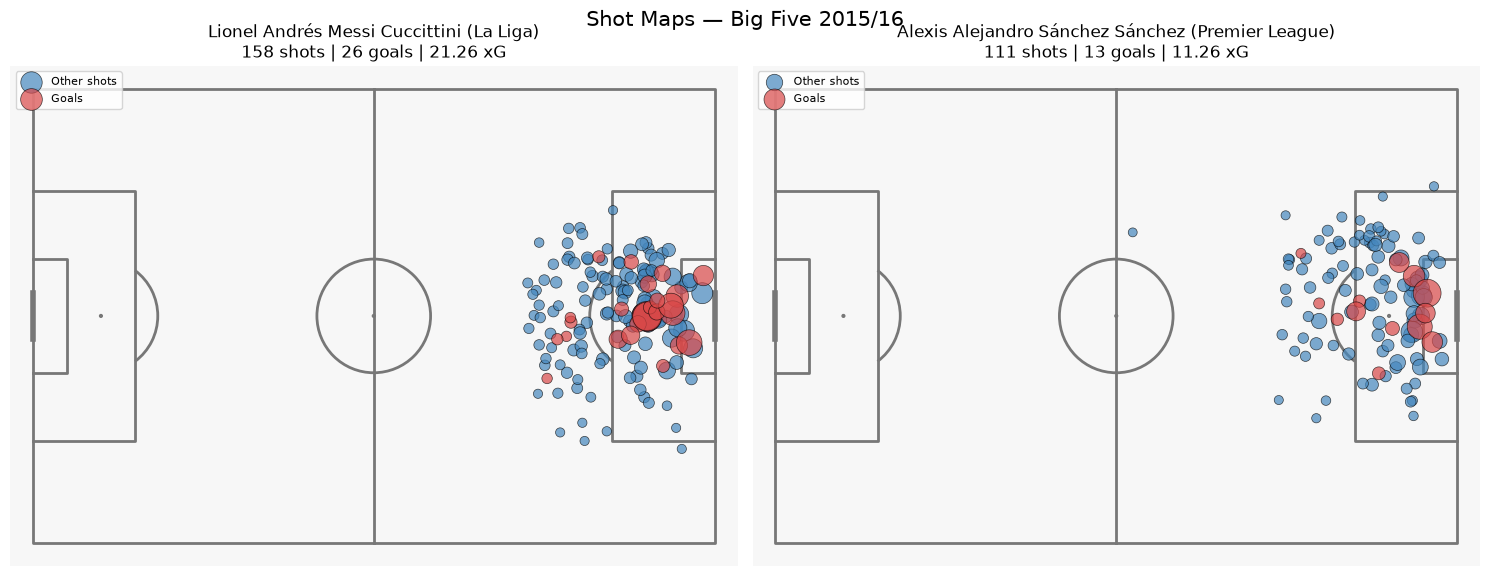

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, key, name in zip(axes, selected_keys, selected_labels):
    events = profile_events(key)
    shots = events.loc[events["is_shot"].fillna(False)].copy()

    shots[["x", "y"]] = extract_xy(shots["location"])
    shots = shots.dropna(subset=["x", "y"])
    shots["shot_xg"] = pd.to_numeric(
        shots["shot_statsbomb_xg"], errors="coerce"
    ).fillna(0)

    goals = shots.loc[shots["is_goal"].fillna(False)]
    other_shots = shots.loc[~shots["is_goal"].fillna(False)]
    pitch.draw(ax=ax)

    for group, color, label in [
        (other_shots, "#4587BD", "Other shots"),
        (goals, "#D94848", "Goals"),
    ]:
        if not group.empty:
            pitch.scatter(
                group["x"], group["y"],
                s=40 + group["shot_xg"] * 500,
                c=color, alpha=0.7,
                edgecolors="black", linewidths=0.5,
                ax=ax, label=label,
            )

    ax.set_title(
        f"{name}\n{len(shots)} shots | "
        f"{len(goals)} goals | "
        f"{shots['shot_xg'].sum():.2f} xG"
    )
    ax.legend(loc="upper left", fontsize=8)

fig.suptitle("Shot Maps — Big Five 2015/16", fontsize=15)
plt.tight_layout()
plt.show()